# Final exam: Math Concepts For Developers #


# Can a robot ignore air resistance when shooting a basketball? #

*Made by: Georgi Ilkov*

In [15]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Introduction ##

Imagine a robot plays basketball. To make the shot, it has to calculate how fast and at what angle to release the ball. The simplest way to calculate it is to use the projectile formula from school physics.

However, the formula assumes that while making the shot, the ball faces **no air**. The real basketball flies through the air and it slows it down. The rim leaves only a few centimeters room for error, so a small difference could turn the shot into a miss.

**Research question:** *If the robot shoots using the no-air formula, will the ball still go in?*

To answer this question, I will:
1. Build an **ideal model** of the shot without any air resistance and derive the angle needed to hit the hoop.
2. Build a **real model** with air resistance. The equations cannot be solved on paper, so I will simulate it using **Euler's method**.
3. Let the robot aim with the ideal model, simulate the shot with the real model and measure how far the ball misses the center of the hoop.


| Quantity | Value |
|---|---|
| Release height | 2.00 m |
| Hoop height | 3.05 m |
| Free-throw distance | 4.60 m |
| Three-point distance | 6.75 m |
| Ball mass | 0.62 kg |
| Ball diameter | 0.24 m |
| Rim diameter | 0.45 m |

## 2. The ideal model (no air resistance)

### 2.1 Assumptions
- The only force acting on the ball is **gravity**, $g = 9.81\ \text{m/s}^2$.
- The ball is treated as a point: we ignore its size and spin.
- The robot releases the ball from the origin $(0, 0)$ with speed $v_0$ at angle $\theta$ above the horizontal.

We place the origin at the release point. The hoop is at $(x_h, y_h)$ then, where $y_h = 3.05 - 2.00 = 1.05$ m.

### 2.2 Equations of motion
Gravity acts only downwards, so:
- the **horizontal** velocity $v_0\cos\theta$ never changes,
- the **vertical** velocity $v_0\sin\theta$ decreases by $g$ every second.

This gives position of the ball at time $t$:

$$x(t) = v_0\cos\theta \cdot t \qquad\qquad y(t) = v_0\sin\theta \cdot t - \frac{1}{2} g t^2$$

In [16]:
G = 9.81
HOOP_HEIGHT = 1.05 # Height of the hoop above the release point, m

### 2.3 The path is a parabola
From the equation of $x(t)$ we can express the time: 
$$t = \frac{x}{v_0\cos\theta}$$

Substituting it into $y(t)$ removes $t$ and gives the height as a function of the horizontal distance:

$$y(x) = x\tan\theta - \frac{g\,x^2}{2v_0^2\cos^2\theta}$$

This is a quadratic function of $x$ with a negative coefficient in front of $x^2$, so the path of the ball is a **parabola opening downward**.

In [17]:
def ideal_y(x, v0, theta_deg):
# Height of the ball (m) at horizontal distance x in the no-air model. 

    theta = np.radians(theta_deg)
    return x * np.tan(theta) - G * x**2 / (2 * v0**2 * np.cos(theta)**2)

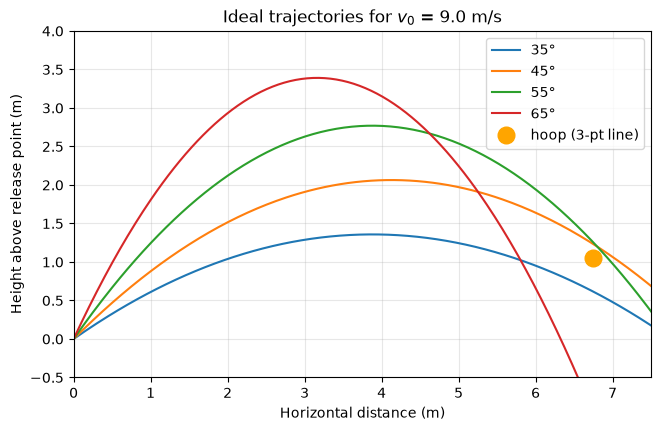

In [23]:
x = np.linspace(0, 7.5, 300)
v0 = 9.0

plt.figure(figsize=(8, 4.5))
for angle in [35, 45, 55, 65]:
    plt.plot(x, ideal_y(x, v0, angle), label=f"{angle}°")

plt.plot(6.75, HOOP_HEIGHT, 'o', color = 'orange', markersize = 12, label = 'hoop (3-pt line)')
plt.xlim(0, 7.5)
plt.ylim(-0.5, 4)
plt.gca().set_aspect("equal")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Height above release point (m)")
plt.title(f'Ideal trajectories for $v_0$ = {v0} m/s')
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In the graph we can see that none of the shots goes exactly through the hoop. The shots at 45° and 55° are the closest, but both pass slightly **above** it, while the shots at 35° and 65° pass **below** it.

This means that the correct angle must lie between a shot that passes below the hoop and one that passes above it. The interesting result is that there are **two** correct answers:
- between **35° and 45°**: a flatter, lower arc,
- between **55° and 65°**: a higher arc.

In the next section we calculate these two angles exactly.